In [79]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [80]:
from wget import download
from os import path, listdir
import pandas as pd
# PARA AUMENTAR EL ANCHO PERMITIDO Y Q NO VEA DATOS CORTADOS
pd.set_option('display.max_colwidth', None)
# PARA DEVOLVER EL ANCHO X DEFAULT 
# pd.set_option('display.max_colwidth', 50)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [81]:
if not path.exists("schema.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/refs/heads/main/packages/archive/2025/schema.csv")
if not path.exists("results.csv"):
  download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")

In [82]:
raw_dataset_results = pd.read_csv("results.csv")
raw_dataset_schema = pd.read_csv("schema.csv")

/tmp/ipykernel_111618/3656956904.py:1: DtypeWarning: Columns (56: JobSatPoints_15_TEXT, 74: DatabaseHaveEntry, 92: DevEnvHaveEntry, 97: SOTagsHaveEntry, 98: SOTagsWant Entry, 105: OfficeStackWantEntry, 109: CommPlatformHaveEntr, 110: CommPlatformWantEntr, 132: SO_Actions_15_TEXT, 162: AIAgentOrchestration, 165: AIAgentObsWrite) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_dataset_results = pd.read_csv("results.csv")


In [83]:
# 1. Definición de las listas de columnas para cada subgrupo
cols_g1 = ['Country', 'WorkExp', 'ConvertedCompYearly', 'CompTotal', 'Currency', 'Age', 'EdLevel', 'Employment', 'YearsCode']
cols_g2 = ['WorkExp', 'AIAcc', 'JobSat', 'AISent', 'AISelect', 'AIThreat', 'AILearnHow']

# Para el Grupo 3 extraemos dinámicamente todas las de JobSatPoints (del 1 al 15 + TEXT) para evitar hardcodearlas
cols_jobsat = [col for col in raw_dataset_results.columns if col.startswith('JobSatPoints')]
cols_g3 = ['NewRole', 'JobSat'] + cols_jobsat

cols_g4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect', 'RemoteWork', 'DevType', 'Industry', 'ICorPM']
#cols_g5 = ['ToolCountWork', 'LanguageChoice', 'DatabaseChoice', 'PlatformChoice', 'WebframeChoice', 'DevEnvsChoice', 'OpSys']

# 2. Creación de los DataFrames independientes para cada subgrupo
# Usamos .copy() para que cada compañero pueda limpiar nulos o transformar datos sin afectar el dataset original

# Subgrupo 1: Perfil Económico (Para Hipótesis A y HU1)
df_perfil_economico = raw_dataset_results[cols_g1].copy()

# Subgrupo 2: Impacto de la IA (Para Hipótesis B y HB1)
df_impacto_ia = raw_dataset_results[cols_g2].copy()

# Subgrupo 3: Cambio de Rol (Para Hipótesis C)
df_cambio_rol = raw_dataset_results[cols_g3].copy()

# Subgrupo 4: Premio Salarial (Para Hipótesis M4)
df_premio_salarial = raw_dataset_results[cols_g4].copy()

# Subgrupo 5: Fondo Técnico (Ecosistema Tecnológico aislado)
#df_fondo_tecnico = raw_dataset_results[cols_g5].copy()

In [84]:
df_premio_salarial.info()

<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  23947 non-null  float64
 1   WorkExp              42893 non-null  float64
 2   OrgSize              34178 non-null  str    
 3   AISelect             33720 non-null  str    
 4   RemoteWork           33780 non-null  str    
 5   DevType              43680 non-null  str    
 6   Industry             33642 non-null  str    
 7   ICorPM               33243 non-null  str    
dtypes: float64(2), str(6)
memory usage: 3.0 MB


Limpieza Estructural: Subgrupo 4 (Premio Salarial y Entorno Organizacional)

Se aplicó una limpieza estructural sobre el Subgrupo 4 fundamentada en los siguientes criterios técnicos:

    Saneamiento del vector principal (ConvertedCompYearly): Este subgrupo fue diseñado exclusivamente para analizar el valor de mercado de los desarrolladores. Las encuestas que no declararon su compensación anual carecen de utilidad para cualquier análisis económico posterior. Por lo tanto, se aplicó una eliminación focalizada (.dropna()) sobre esta columna, garantizando que todas las observaciones retengan su variable dependiente.

    Filtro lógico inferior de ingresos (ConvertedCompYearly): El análisis estadístico descriptivo reveló la existencia de valores anuales imposibles (ej. $1 USD). Se estableció un piso conservador de $1.000 USD anuales para descartar respuestas de relleno o errores de magnitud (usuarios que ingresaron su tarifa por hora en lugar de la compensación anual), garantizando la calidad del vector objetivo.

    Filtro lógico de valores atípicos (WorkExp): Se identificaron errores de carga sistemáticos en los años de experiencia, con usuarios declarando entre 90 y 100 años de trayectoria. Para evitar que estos valores lógicamente imposibles generen un apalancamiento desproporcionado en los futuros modelos predictivos, se estableció un umbral máximo de 60 años. Las observaciones que superaron este límite fueron convertidas a valores nulos y posteriormente eliminadas del subgrupo.

In [85]:
import numpy as np

df_premio_salarial_limpio = df_premio_salarial.dropna(subset=['ConvertedCompYearly']).copy()

umbral_salario_min = 1000 # USD anuales (ver si ajustar a otros valores)
df_premio_salarial_limpio = df_premio_salarial_limpio[df_premio_salarial_limpio['ConvertedCompYearly'] >= umbral_salario_min].copy()

umbral_experiencia = 60
df_premio_salarial_limpio.loc[df_premio_salarial_limpio['WorkExp'] > umbral_experiencia, 'WorkExp'] = np.nan

df_premio_salarial_limpio = df_premio_salarial_limpio.dropna(subset=['WorkExp']).copy()

print(f"Total de observaciones tras la limpieza general del Subgrupo 4: {len(df_premio_salarial_limpio)}")
df_premio_salarial_limpio.info()

Total de observaciones tras la limpieza general del Subgrupo 4: 22804
<class 'pandas.DataFrame'>
Index: 22804 entries, 0 to 49122
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  22804 non-null  float64
 1   WorkExp              22804 non-null  float64
 2   OrgSize              20375 non-null  str    
 3   AISelect             22166 non-null  str    
 4   RemoteWork           20281 non-null  str    
 5   DevType              22804 non-null  str    
 6   Industry             22131 non-null  str    
 7   ICorPM               20067 non-null  str    
dtypes: float64(2), str(6)
memory usage: 1.6 MB


-----------------------------------------------
Ahora si empieza analsis de la hipotesis:

Paso 1: Introducción a la Hipótesis Multivariada planteada por nostros:

¿Existe un "premio económico" significativo en el mercado laboral asociado al uso de herramientas de Inteligencia Artificial, a igual nivel de experiencia y tamaño de empresa?

Para validar esta hipótesis, analizaremos el Subgrupo 4 (df_premio_salarial_limpio). Plantearemos un modelo predictivo evaluando las siguientes variables:

    Variable Objetivo (ConvertedCompYearly): Variable cuantitativa continua que representa el salario anual estandarizado en USD.

    Variable Predictora Continua (WorkExp): Años de experiencia profesional (previamente saneada de valores atípicos lógicamente imposibles).

    Variables Predictoras Categóricas (OrgSize y AISelect): Variables cualitativas nominales que indican el tamaño de la organización y la adopción de IA, respectivamente.


Dado que los algoritmos de regresión lineal múltiple asumen normalidad y son sensibles a valores extremos, realizaremos una exploración visual del salario para determinar si requiere transformaciones. Asimismo, las variables cualitativas deberán ser codificadas numéricamente.

Paso 2: Primer vistazo sobre las variables con las que vamos a trabajar.

Empecemos mirando visualmente y con un describe la distribucion de los salarios.

Estadísticas descriptivas del Salario (Crudo):
count        $22,804
mean        $105,851
std         $468,112
min           $1,000
25%          $43,654
50%          $78,890
75%         $125,000
max      $50,000,000
Name: ConvertedCompYearly, dtype: str
--------------------------------------------------


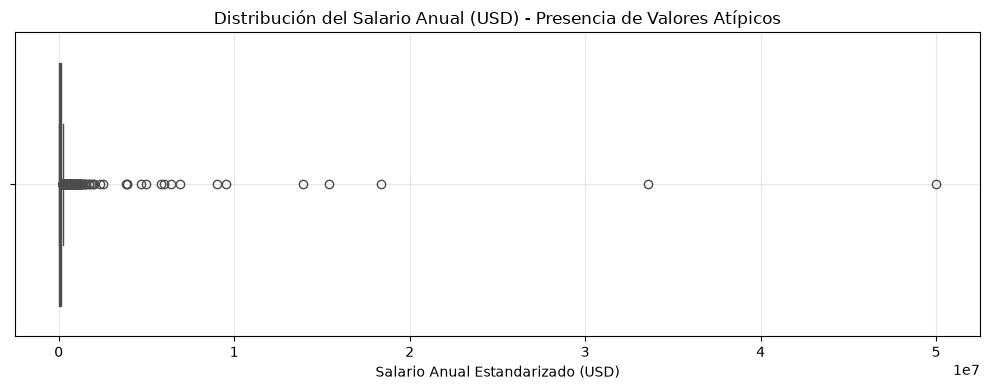

In [86]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prueba analítica: Estadísticas descriptivas (formateadas para leer los USD)
resumen_salarial = df_premio_salarial_limpio['ConvertedCompYearly'].describe()
print("Estadísticas descriptivas del Salario (Crudo):")
print(resumen_salarial.apply(lambda x: f"${x:,.0f}"))
print("-" * 50)

# 2. Prueba visual: Boxplot evidenciando el sesgo positivo
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_premio_salarial_limpio['ConvertedCompYearly'], color='#4C72B0')

plt.title('Distribución del Salario Anual (USD) - Presencia de Valores Atípicos')
plt.xlabel('Salario Anual Estandarizado (USD)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Al analizar las estadísticas descriptivas y el diagrama de caja, se observa una severa asimetría positiva (sesgo hacia la derecha).

La inmensa mayoría de los datos (la caja intercuartílica) se encuentra comprimida en los valores más bajos, mientras que el promedio se ve fuertemente arrastrado hacia arriba por outliers extremos que declaran ingresos de decenas de millones de dólares.

Si ingresamos estos datos crudos a una Regresión Lineal, estos extremos deformarán el cálculo de los coeficientes beta y violarán los supuestos de homocedasticidad y normalidad de los errores. Por ende, la evidencia empírica justifica y hace obligatoria la aplicación de una transformación logarítmica para el modelado.

Veamos los posibles valores para AISelect y OrgSize, ya que son preguntas Multiple Choise tienen un conjunto de posibles respuestas:

In [87]:
df_premio_salarial_limpio["AISelect"].value_counts()

AISelect
Yes, I use AI tools daily                      10881
Yes, I use AI tools weekly                      4050
No, and I don't plan to                         3247
Yes, I use AI tools monthly or infrequently     2949
No, but I plan to soon                          1039
Name: count, dtype: int64

In [88]:
df_premio_salarial_limpio["OrgSize"].value_counts()

OrgSize
20 to 99 employees                                    4119
100 to 499 employees                                  3899
Less than 20 employees                                3150
10,000 or more employees                              3089
1,000 to 4,999 employees                              2667
500 to 999 employees                                  1538
5,000 to 9,999 employees                              1029
Just me - I am a freelancer, sole proprietor, etc.     607
I don’t know                                           277
Name: count, dtype: int64

Paso 3: Acondicionamiento de Variables y Transformaciones Matemáticas

Para que el algoritmo de Mínimos Cuadrados Ordinarios (MCO/OLS) pueda procesar los datos respetando su naturaleza, es necesario acondicionar la matriz final aplicando tres tratamientos específicos:

    Eliminación focalizada de nulos y categorías ruidosas: Se descartarán las filas con valores faltantes en OrgSize y AISelect para evitar sesgos por imputación. Asimismo, se eliminará la respuesta "I don’t know" en OrgSize, ya que no representa una magnitud corporativa real y rompe la linealidad de la variable.

    Transformación Logarítmica del Salario: Dado que la variable dependiente (ConvertedCompYearly) posee una asimetría positiva severa por valores atípicos superiores, se aplicará una transformación logarítmica (log(1+x)). Esto estabiliza la varianza de los residuos y permite cumplir con los supuestos de linealidad y homocedasticidad exigidos por la regresión múltiple.

    Codificación Ordinal (Ordinal Encoding): A diferencia de las variables nominales puras, OrgSize y AISelect son variables cualitativas ordinales; poseen una jerarquía intrínseca (menor a mayor tamaño, y nula a alta frecuencia de uso). Para preservar esta progresión matemática, no se utilizará One-Hot Encoding. En su lugar, se mapearán las categorías a valores numéricos secuenciales enteros (ej. de 1 a 8 para el tamaño de la empresa, y de 1 a 5 para la frecuencia de IA). Esto le permite al modelo lineal interpretar el impacto de "subir un escalón" en estas jerarquías.

In [89]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Aislamiento y eliminación de nulos
cols_m4 = ['ConvertedCompYearly', 'WorkExp', 'OrgSize', 'AISelect']
df_m4 = df_premio_salarial_limpio[cols_m4].dropna().copy()

# Eliminamos la respuesta que no aporta jerarquía
df_m4 = df_m4[df_m4['OrgSize'] != 'I don’t know'].copy()

# 2. Transformación Logarítmica del Salario
df_m4['Log_Salary'] = np.log1p(df_m4['ConvertedCompYearly'])

# 3. Codificación Ordinal (Mapeo de jerarquías a números enteros)
diccionario_orgsize = {
    'Just me - I am a freelancer, sole proprietor, etc.': 1,
    'Less than 20 employees': 2,
    '20 to 99 employees': 3,
    '100 to 499 employees': 4,
    '500 to 999 employees': 5,
    '1,000 to 4,999 employees': 6,
    '5,000 to 9,999 employees': 7,
    '10,000 or more employees': 8
}

diccionario_aiselect = {
    "No, and I don't plan to": 1,
    "No, but I plan to soon": 2,
    "Yes, I use AI tools monthly or infrequently": 3,
    "Yes, I use AI tools weekly": 4,
    "Yes, I use AI tools daily": 5
}

# Aplicamos los diccionarios y forzamos el tipo entero por seguridad matemática
df_m4['OrgSize_Rank'] = df_m4['OrgSize'].map(diccionario_orgsize).astype(int)
df_m4['AISelect_Rank'] = df_m4['AISelect'].map(diccionario_aiselect).astype(int)



In [92]:
df_m4.head(1)

,ConvertedCompYearly,WorkExp,OrgSize,AISelect,Log_Salary,OrgSize_Rank,AISelect_Rank
0,61256.0,8.0,20 to 99 employees,"Yes, I use AI tools monthly or infrequently",11.022833,3,3


Paso 4: Entrenamiento y Evaluación del Modelo (Regresión Lineal Múltiple)

Con la matriz df_m4 completamente numérica y acondicionada (WorkExp, OrgSize_Rank y AISelect_Rank como predictores ordinales/continuos, y Log_Salary como variable respuesta logarítmica), procederemos a construir el modelo estadístico.

Dado que nuestro objetivo es predecir una variable continua evaluando múltiples características en simultáneo, utilizaremos el algoritmo de Regresión Lineal Múltiple. A diferencia del aprendizaje automático enfocado puramente en predicción ciega, adoptaremos un enfoque de análisis multivariado estadístico clásico: utilizaremos la librería statsmodels para estimar los coeficientes mediante el método de Mínimos Cuadrados Ordinarios (MCO/OLS) y evaluar formalmente los p-valores, lo que nos permitirá cuantificar el impacto (el "premio") de cada variable independiente sobre el salario.

In [90]:
import statsmodels.api as sm

# Definimos variable objetivo (y) y variables predictoras (X)
# Usamos las variables limpias y transformadas
y = df_m4['Log_Salary']
X = df_m4[['WorkExp', 'OrgSize_Rank', 'AISelect_Rank']]

# Añadimos la constante requerida por la regresión lineal para calcular la ordenada al origen
X = sm.add_constant(X)

# Inicializamos y ajustamos (entrenamos) el modelo OLS
modelo_m4 = sm.OLS(y, X).fit()

# Imprimimos el resumen estadístico
print(f"Total de observaciones utilizadas: {len(df_m4)}")
print("-" * 50)
print(modelo_m4.summary())

Total de observaciones utilizadas: 19557
--------------------------------------------------
                            OLS Regression Results                            
Dep. Variable:             Log_Salary   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                     1388.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        06:38:10   Log-Likelihood:                -26949.
No. Observations:               19557   AIC:                         5.391e+04
Df Residuals:                   19553   BIC:                         5.394e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------

Paso 5: Análisis de Resultados de Regresion Lineal multiple:

Para evaluar la existencia de un "premio salarial" por el uso de Inteligencia Artificial, analizaremos los resultados del modelo de Regresión Lineal Múltiple (MCO), evaluando los coeficientes bajo la condición ceteris paribus (aislando el efecto de cada variable mientras las demás se mantienen constantes).

1. Bondad de Ajuste (Capacidad Explicativa del Modelo)

R^2 y R^2 Ajustado: El valor es de 0.176 (17.6%). Esto significa que las variables elegidas (Experiencia, Tamaño de Empresa y Uso de IA) logran explicar el 17.6% de la varianza total de los salarios logarítmicos. Si bien parece un número bajo, es un valor completamente normal y esperado en modelos de ciencias sociales o encuestas salariales (donde intervienen cientos de factores no medidos como el país, la tecnología específica o habilidades blandas).

Significatividad Global (Estadístico F): El valor de Prob(F-statistic) es 0.00. Al ser menor al nivel de significancia típico alpha = 0.05, rechazamos la hipótesis nula conjunta, confirmando que el modelo global es estadísticamente válido y que las variables predictoras, en conjunto, aportan información real para estimar el salario.   

2. Análisis de Coeficientes y "El Premio Salarial"

La tabla de coeficientes (coef) te entrega los pesos exactos beta para armar tu ecuación predictiva lineal.  

Significatividad Individual (Test t): La columna P>|t| muestra un valor de 0.000 para absolutamente todos los predictores (y la constante). Como es menor a 0.05, confirmamos que la experiencia, el tamaño de la empresa y la frecuencia de uso de IA tienen un impacto real y estadísticamente significativo sobre el sueldo de un desarrollador. 
 
Impacto de la IA (AISelect_Rank): Aquí está el hallazgo crucial. El coeficiente es negativo (-0.0306). Como nosotros ordenamos la variable ordinal de 1 (No usa) a 5 (Usa a diario), este coeficiente significa que, asumiendo que la experiencia y el tamaño de la empresa se mantienen constantes, a medida que aumenta la frecuencia de uso de IA, el salario disminuye. Esto refuta la idea del premio salarial tal como la habíamos planteado.  

Impacto de la Experiencia y Empresa (WorkExp y OrgSize_Rank): Ambos tienen coeficientes positivos (0.0381 y 0.1049 respectivamente). Esto confirma la lógica económica tradicional: a mayor experiencia y a mayor tamaño de empresa corporativa, mayor es la expectativa salarial.  

3. Diagnóstico de los Errores (Supuestos del Modelo)La parte inferior del resumen evalúa los residuos (errores) del modelo, verificando si cumplimos los supuestos para que la estimación sea válida.

Test de Normalidad (Omnibus y Jarque-Bera): Ambos tests arrojan un p-valor (Prob) de 0.00. Esto indica que los errores no se distribuyen de forma perfectamente normal (una campana de Gauss ideal), algo muy común al tener tantas observaciones (casi 20.000 datos).

Durbin-Watson: Arroja un valor de 1.950. Como está extremadamente cerca de 2, confirma que no existe autocorrelación en los residuos, cumpliendo con el supuesto de independencia de los errores.

Análisis y Discusión de Resultados

1. Hipótesis rechazada y por qué: Rechazamos formalmente la Hipótesis M4. 

La premisa inicial suponía la existencia de un "premio salarial" donde el uso de Inteligencia Artificial incrementaría el sueldo del desarrollador. Sin embargo, el modelo de Regresión Lineal Múltiple arrojó un coeficiente negativo y estadísticamente significativo (-0.0306, con un p-valor de 0.000) para la variable AISelect_Rank. Esto demuestra matemáticamente que, a igual nivel de experiencia y tamaño de empresa, una mayor frecuencia en el uso de IA no aumenta el sueldo, sino que está asociada a una disminución del salario estimado.

2. Discusión de los resultados y justificación del rechazo:

¿Por qué podría pasar esto en el mercado real?

Este fenómeno contraintuitivo puede explicarse por la naturaleza de los roles técnicos: los perfiles con los salarios más altos (Arquitectos de Software, Tech Leads o Managers) dedican la mayor parte de su tiempo al diseño de sistemas, liderazgo y reuniones, utilizando asistentes de código con menor frecuencia diaria que los desarrolladores Junior/Semi-Senior, quienes dependen más de estas herramientas para maximizar su volumen de producción de código.

El sesgo geográfico (Variable Omitida): Como no incluimos la variable Country en este modelo, es muy probable que desarrolladores de regiones con sueldos más bajos (Latinoamérica, India) estén adoptando la IA masivamente y a diario para ser más competitivos y rápidos, mientras que los desarrolladores de EE.UU. (que ganan muchísimo más) tienen una adopción más distribuida.

Conclusión de negocio: Rechazamos la hipótesis porque la IA, hoy en día, no funciona como una habilidad exclusiva que las empresas premian con un bono salarial. Por el contrario, su uso intensivo diario actúa en los datos como un indicador (proxy) de roles más operativos o de menor jerarquía en la cadena de valor del desarrollo de software.
